# Test 3 - receiver outage (10 h): analysis

Put this notebook next to the unpacked `T3` folder, or inside it with the data files:

```
T3/test3_outage_20261022T0423Z.csv
T3/export_pi5_127.0.0.1.jsonl.gz
T3/export_pi5_netmon-receiver.jsonl.gz
T3/export_vmagent_pi.jsonl.gz
T3/journal.txt.gz
```

Run all cells. Figures are shown here and saved to `figures/` as PDF (for LaTeX) and PNG.

**Note on the test log:** the script read vmagent's `pending_data_bytes` as 0 (an `awk` field bug for
metrics with two labels), so the buffer and catch-up below come from **vmagent's own metrics,
scraped by the local VictoriaMetrics every 15 s** (`export_vmagent_pi.jsonl.gz`), not from the log.

In [1]:
%matplotlib inline
import gzip, json, collections, os, glob, datetime as dt
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
from IPython.display import Markdown, display

DATA = 'T3' if os.path.isdir('T3') else '.'
LOG = sorted(glob.glob(os.path.join(DATA, 'test3_outage_*.csv')))[-1]
print('data folder:', os.path.abspath(DATA)); print('test log   :', LOG)
OUT = 'figures'
os.makedirs(OUT, exist_ok=True)
RATE_LIMIT = 62_500          # vmagent -remoteWrite.rateLimit (bytes/s)
DISK_MAX = 9e9               # vmagent -remoteWrite.maxDiskUsagePerURL

plt.rcParams.update({
    'font.family': 'serif', 'font.serif': ['Times New Roman', 'Liberation Serif', 'DejaVu Serif'],
    'font.size': 10, 'axes.axisbelow': True,
    'axes.spines.top': False, 'axes.spines.right': False,
    'axes.edgecolor': '#52514e', 'axes.labelcolor': '#0b0b0b',
    'xtick.color': '#52514e', 'ytick.color': '#52514e',
    'axes.grid': True, 'grid.color': '#e6e5e1', 'grid.linewidth': 0.6,
    'savefig.dpi': 300, 'figure.dpi': 120})
DARK_GREEN, BLACK, BLUE, ORANGE = '#1b7a34', '#000000', '#2a78d6', '#c4511a'

def save(fig, name):
    for ext in ('pdf', 'png'):
        fig.savefig(os.path.join(OUT, f'{name}.{ext}'), bbox_inches='tight')

def key(target, handles, labels, ncol=1, **kw):
    leg = target.legend(handles, labels, title='Key', title_fontproperties={'weight': 'bold', 'size': 9},
                        fontsize=8.5, ncol=ncol, frameon=True, edgecolor=BLACK, fancybox=False,
                        framealpha=1, **kw)
    leg.get_frame().set_linewidth(0.8)
    return leg

data folder: C:\Users\rich\OneDrive - University of Cape Town\1_FINAL_YEAR\EEE4022S Research Project\T3\T3
test log   : T3\test3_outage_20261022T0423Z.csv


## Load the test log and the exported data

In [2]:
def ms(s):
    return dt.datetime.fromisoformat(s.replace('Z', '+00:00')).timestamp() * 1000
def hms(t):
    return dt.datetime.fromtimestamp(t / 1000, dt.timezone.utc).strftime('%H:%M:%S')

log = [line.strip().split(',') for line in open(LOG)][1:]
T0 = next(ms(r[1]) for r in log if r[0] == 'start')               # vmagent + netmon started
T_END = ms(log[-1][1])                                             # vmagent stopped

def load(fn):
    series = collections.defaultdict(list)
    for line in gzip.open(fn, 'rt'):
        o = json.loads(line)
        series[o['metric']['__name__']].append(o)
    return series

pi = load(os.path.join(DATA, 'export_pi5_127.0.0.1.jsonl.gz'))
rx = load(os.path.join(DATA, 'export_pi5_netmon-receiver.jsonl.gz'))
vm = load(os.path.join(DATA, 'export_vmagent_pi.jsonl.gz'))

def total(src, name):
    """Sum of all series of one metric at each timestamp."""
    c = collections.defaultdict(float)
    for o in src.get(name, []):
        for t, v in zip(o['timestamps'], o['values']):
            if v is not None:
                c[t] += v
    return sorted(c.items())

pend = total(vm, 'vmagent_remotewrite_pending_data_bytes')
sent = total(vm, 'vmagent_remotewrite_bytes_sent_total')
rlim = total(vm, 'vmagent_remotewrite_rate_limit_reached_total')
hrs = lambda t: (t - T0) / 3.6e6

# outage = from start until the last scrape before data was first sent
t_first_sent = next(t for t, v in sent if v > 0)
t_peak = max((t for t, v in pend if t < t_first_sent), key=lambda t: dict(pend)[t])
peak = dict(pend)[t_peak]
t_empty = next(t for t, v in pend if t > t_first_sent and v == 0)

# receiver send failures (journal)
fails = [ms(l.split()[0]) for l in gzip.open(os.path.join(DATA, 'journal.txt.gz'), 'rt') if "couldn't send" in l]
print(f'start {hms(T0)}  first failed send {hms(fails[0])}  last failed send {hms(fails[-1])}  ({len(fails)} log lines)')
print(f'peak buffer {peak/1e6:.2f} MB at {hms(t_peak)};  first bytes sent by {hms(t_first_sent)};  buffer empty at {hms(t_empty)}')

start 04:24:08  first failed send 04:24:39  last failed send 14:24:15  (2643 log lines)
peak buffer 9.67 MB at 14:24:01;  first bytes sent by 14:24:16;  buffer empty at 14:26:46


## Figure 1 - buffer growth during the outage

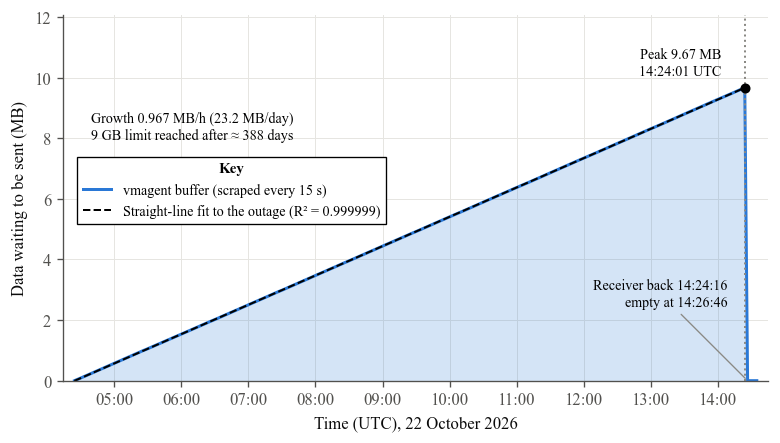

growth 0.9674 MB/h, R² 0.999999, 9 GB lasts 388 days (12.8 months); outage 04:24:08-14:24:01, receiver back 14:24:16, empty 14:26:46 UTC


In [9]:
import matplotlib.dates as mdates
utc = lambda t: dt.datetime.fromtimestamp(t / 1000, dt.timezone.utc)
# straight-line fit over the outage only (start -> peak)
out = [(t, v) for t, v in pend if T0 <= t <= t_peak]
x = np.array([hrs(t) for t, v in out]); y = np.array([v / 1e6 for t, v in out])
k, c = np.polyfit(x, y, 1)
r2 = 1 - np.var(y - (k * x + c)) / np.var(y)
days_9gb = DISK_MAX / 1e6 / (k * 24)
# the whole test: outage, catch-up and normal running until the end
full = [(t, v) for t, v in pend if T0 <= t <= T_END]
t_rx = fails[-1] + 1_000                                   # receiver back (just after the last failed send)

fig, ax = plt.subplots(figsize=(6.6, 3.8))
ax.fill_between([utc(t) for t, v in full], [v / 1e6 for t, v in full], color=BLUE, alpha=0.2, lw=0)
ax.plot([utc(t) for t, v in full], [v / 1e6 for t, v in full], color=BLUE, lw=1.8)
ax.plot([utc(T0), utc(t_peak)], [c, k * hrs(t_peak) + c], color=BLACK, lw=1.2, ls='--')
ax.plot(utc(t_peak), peak / 1e6, 'o', ms=5, color=BLACK, zorder=3)
ax.annotate(f'Peak {peak/1e6:.2f} MB\n{hms(t_peak)} UTC', (utc(t_peak), peak / 1e6), xytext=(-14, 6),
            textcoords='offset points', ha='right', va='bottom', fontsize=8.5)
ax.axvline(utc(t_rx), color='#8a8984', ls=':', lw=1.2)
ax.annotate(f'Receiver back {hms(t_rx)}\nempty at {hms(t_empty)}', (utc(t_empty), 0), xytext=(-12, 45),
            textcoords='offset points', ha='right', fontsize=8.5,
            arrowprops=dict(arrowstyle='-', color='#8a8984', lw=0.8))
ax.text(utc(T0 + 15 * 60_000), 0.92 * peak / 1e6,
        f'Growth {k:.3f} MB/h ({k*24:.1f} MB/day)\n9 GB limit reached after ≈ {days_9gb:.0f} days',
        fontsize=8.5, va='top')
ax.set_xlim(utc(T0 - 10 * 60_000), utc(T_END + 10 * 60_000)); ax.set_ylim(0, peak / 1e6 * 1.25)
ax.xaxis.set_major_formatter(mdates.DateFormatter('%H:%M', tz=dt.timezone.utc))
ax.xaxis.set_major_locator(mdates.HourLocator(byhour=range(0, 24, 1), tz=dt.timezone.utc))
ax.set_xlabel(f'Time (UTC), {utc(T0):%d %B %Y}'); ax.set_ylabel('Data waiting to be sent (MB)')
key(ax, [Line2D([], [], color=BLUE, lw=1.8), Line2D([], [], color=BLACK, ls='--', lw=1.2)],
    ['vmagent buffer (scraped every 15 s)', f'Straight-line fit to the outage (R² = {r2:.6f})'],
    loc='center left', bbox_to_anchor=(0.01, 0.52))
fig.tight_layout(); save(fig, 't3_buffer_growth'); plt.show()
print(f'growth {k:.4f} MB/h, R² {r2:.6f}, 9 GB lasts {days_9gb:.0f} days ({days_9gb/30.4:.1f} months); '
      f'outage {hms(T0)}-{hms(t_peak)}, receiver back {hms(t_rx)}, empty {hms(t_empty)} UTC')

## Figure 2 - catch-up after the receiver returned

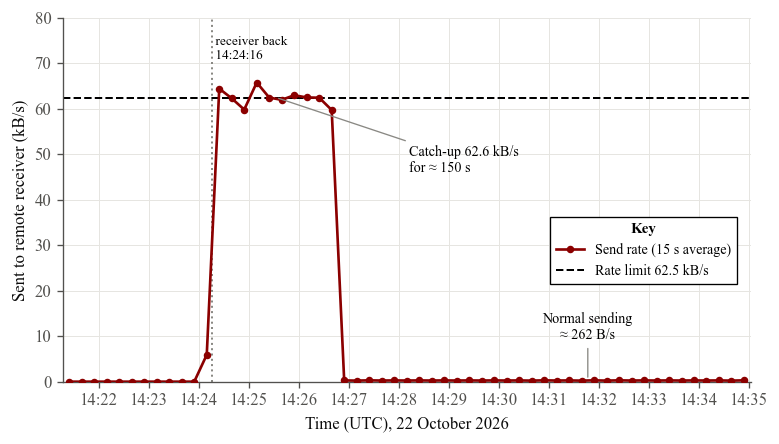

catch-up rate 62,557 B/s (limit 62,500); normal afterwards 262 B/s; rate-limit hits 150


In [10]:
import matplotlib.dates as mdates
DARK_RED = '#8b0000'
# window: 3 min before the first data was sent until the end of the test
w0, w1 = t_first_sent - 3 * 60_000, T_END
utc = lambda t: dt.datetime.fromtimestamp(t / 1000, dt.timezone.utc)
sx = [(t, v) for t, v in sent if w0 <= t <= w1]
rate = [((t0 + t1) / 2, (v1 - v0) / ((t1 - t0) / 1000)) for (t0, v0), (t1, v1) in zip(sx, sx[1:])]   # B/s, plotted mid-interval
t_rx = fails[-1] + 1_000                                   # just after the last failed send
sec = lambda t: (t - t_first_sent) / 1000

fig, ax = plt.subplots(figsize=(6.6, 3.8))
ax.plot([utc(t) for t, v in rate], [v / 1000 for t, v in rate], 'o-', ms=3.5, color=DARK_RED, lw=1.6, zorder=3)
ax.axhline(RATE_LIMIT / 1000, color=BLACK, ls='--', lw=1.2, zorder=2)
ax.axvline(utc(t_rx), color='#8a8984', ls=':', lw=1.2)
ax.text(utc(t_rx), 76, f' receiver back\n {hms(t_rx)}', fontsize=8, va='top', ha='left')
steady = [v for t, v in rate if t_first_sent + 15_000 < t < t_empty - 15_000]   # full 15 s intervals inside the catch-up
after = [v for t, v in rate if t > t_empty + 30_000]
ax.annotate(f'Catch-up {np.mean(steady)/1000:.1f} kB/s\nfor ≈ {sec(t_empty):.0f} s',
            (utc((t_first_sent + t_empty) / 2), np.mean(steady) / 1000), xytext=(80, -45),
            textcoords='offset points', fontsize=8.5, arrowprops=dict(arrowstyle='-', color='#8a8984', lw=0.8))
ax.annotate(f'Normal sending\n≈ {np.mean(after):.0f} B/s', (utc(t_empty + 5 * 60_000), np.mean(after) / 1000),
            xytext=(0, 25), textcoords='offset points', ha='center', fontsize=8.5,
            arrowprops=dict(arrowstyle='-', color='#8a8984', lw=0.8))
ax.set_ylim(0, 80); ax.set_ylabel('Sent to remote receiver (kB/s)')
ax.set_xlim(utc(w0), utc(w1))
ax.xaxis.set_major_formatter(mdates.DateFormatter('%H:%M', tz=dt.timezone.utc))
ax.xaxis.set_major_locator(mdates.MinuteLocator(byminute=range(0, 60, 1), tz=dt.timezone.utc))
ax.set_xlabel('Time (UTC), 22 October 2026')
key(ax, [Line2D([], [], color=DARK_RED, lw=1.6, marker='o', ms=3.5), Line2D([], [], color=BLACK, ls='--', lw=1.2)],
    ['Send rate (15 s average)', 'Rate limit 62.5 kB/s'],
    loc='center right', bbox_to_anchor=(0.99, 0.36))
fig.tight_layout(); save(fig, 't3_catchup'); plt.show()

rl = dict(rlim)
print(f'catch-up rate {np.mean(steady):,.0f} B/s (limit {RATE_LIMIT:,}); normal afterwards {np.mean(after):.0f} B/s; '
      f'rate-limit hits {rl[t_empty] - rl[t_first_sent - 15_000]:.0f}')


## Table 1 - summary

In [5]:
def samples(src):
    cnt = collections.Counter()
    for name, objs in src.items():
        for o in objs:
            k_ = tuple(sorted(o['metric'].items()))
            for t in o['timestamps']:
                cnt[(k_, t)] += 1
    return cnt
a, b = samples(pi), samples(rx)
last = lambda name: (total(vm, name) or [(0, 0)])[-1][1]
wifi = sorted(t for o in pi['wifi_status'] for t in o['timestamps'])
gaps = sum(1 for t0, t1 in zip(wifi, wifi[1:]) if t1 - t0 > 30_000)
rows = [('Outage length', f'{hrs(t_peak):.2f} h ({hms(T0)}–{hms(t_peak)} UTC)'),
        ('Peak buffer', f'{peak/1e6:.2f} MB'),
        ('Buffer growth', f'{k:.3f} MB/h ({k*24:.1f} MB/day), R² = {r2:.6f}'),
        ('Time to fill the 9 GB limit', f'≈ {days_9gb:.0f} days ({days_9gb/30.4:.1f} months)'),
        ('Catch-up time', f'≈ {sec(t_empty):.0f} s (15 s scrape resolution)'),
        ('Catch-up send rate', f'{np.mean(steady):,.0f} B/s (limit {RATE_LIMIT:,} B/s)'),
        ('Dropped (packets / samples / queue bytes)',
         f"{last('vmagent_remotewrite_packets_dropped_total'):.0f} / {last('vmagent_remotewrite_samples_dropped_total'):.0f} / {last('vm_persistentqueue_bytes_dropped_total'):.0f}"),
        ('Samples on Pi / receiver', f'{sum(a.values()):,} / {sum(b.values()):,}'),
        ('Missing / extra / duplicates on receiver',
         f'{len(set(a)-set(b))} / {len(set(b)-set(a))} / {sum(n-1 for n in b.values() if n > 1)}'),
        ('Wi-Fi gaps longer than 30 s', str(gaps))]
display(Markdown('\n'.join(['| Result | Value |', '|---|---|'] + [f'| {x} | {y} |' for x, y in rows])))

| Result | Value |
|---|---|
| Outage length | 10.00 h (04:24:08–14:24:01 UTC) |
| Peak buffer | 9.67 MB |
| Buffer growth | 0.967 MB/h (23.2 MB/day), R² = 0.999999 |
| Time to fill the 9 GB limit | ≈ 388 days (12.8 months) |
| Catch-up time | ≈ 150 s (15 s scrape resolution) |
| Catch-up send rate | 62,557 B/s (limit 62,500 B/s) |
| Dropped (packets / samples / queue bytes) | 0 / 0 / 0 |
| Samples on Pi / receiver | 273,305 / 273,305 |
| Missing / extra / duplicates on receiver | 0 / 0 / 0 |
| Wi-Fi gaps longer than 30 s | 0 |

**Queue file after the catch-up (checked on the Pi, 14:59 UTC):** the queue folder still held one
9,712,959-byte file, but `metainfo.json` showed `ReaderOffset = WriterOffset = 9712959`. All buffered data
had been read and sent; the folder size is therefore **not** a measure of unsent data, whereas
`pending_data_bytes` is.